Matplotlib is building the font cache; this may take a moment.


Template pixel size: 22.9814 um
Processing method: TM_CCOEFF_NORMED
Starting super fine tuning...
TM_CCOEFF_NORMED done - GIF and PNG created


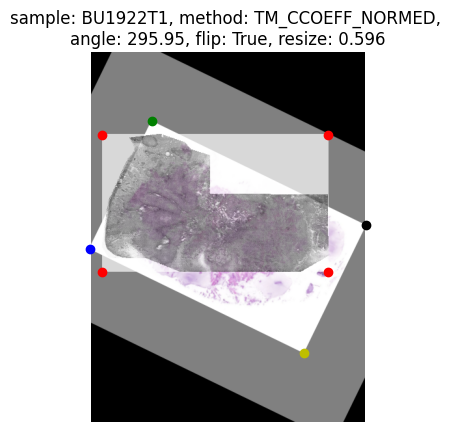

NotADirectoryError: [Errno 20] Not a directory: '/Users/nadiamoltolliso/Desktop/mortadela_local/mortadela_samples/.DS_Store/.DS_Store_prop.txt'

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from mortadela_functions import *

# sample_name = "BU204T3"
directory = "/Users/nadiamoltolliso/Desktop/mortadela_local/mortadela_samples"
top_picks = 10
maldi_pixel_size = 30
threads = 12


os.makedirs(f"{directory}/outputs", exist_ok=True)

for sample_name in os.listdir(directory):
    if sample_name == "outputs" or sample_name == ".DS_Store":
    # if sample_name != "BU1627T2":
        continue

    info_file = f"{directory}/{sample_name}/{sample_name}_prop.txt"
    template_pixel_size = get_template_pixel_size(info_file)
    if template_pixel_size == 0:
        print("Error reading pixel size from info file")
        exit(1)
    print(f"Template pixel size: {template_pixel_size} um")

    template_original, template_BW_original, maldi_o, scaling_factor, biggest_add = process_images(sample_name, directory, template_pixel_size, maldi_pixel_size)

    match_and_overlay_gif_and_png(template_original, template_BW_original, maldi_o, scaling_factor, biggest_add, sample_name, directory, top_picks, threads)

